<style>
h1, h2, h3, h4, h5, h6 {
    direction: rtl !important;
    text-align: right !important;
    unicode-bidi: plaintext;
}
</style>

## <div style="direction:rtl;text-align:right">  بخش سوم؛ پردازش و بازیابی ویدیو </div>

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#### <div style="direction:rtl;text-align:right"> سوال اول؛ بارگذاری و بررسی مشخصات ویدیو </div>

In [38]:
cap = cv2.VideoCapture("park_video.mp4")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
frame_width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
frame_height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
total_time = frame_count / fps

print(f'Frame Count: {frame_count}')
print(f'Frame Rate: {fps} FPS')
print(f'Frame Width: {frame_width} px')
print(f'Frame Height: {frame_height} px')
print(f'Video Time: {total_time} s')

cap.release()

Frame Count: 450.0
Frame Rate: 30.0 FPS
Frame Width: 1280.0 px
Frame Height: 720.0 px
Video Time: 15.0 s


<div style="direction:rtl;text-align:right">
در OpenCV با دستور Videocapture می‌توانیم ویدیو را بخوانیم.
<br/>
برای بدست آوردن هر یک از مشخصات  تصویر، OpenCV یک متود مخصوص دارد که مشخصه را گزارش می‌کند.
<br/>
فقط برای نمایش زمان ویدیو، تعداد کل فریم‌های تصویر را بر نرخ فریم تقسیم کردیم تا تعداد ثانیه‌های ویدیو بدست آید. سپس این مقدار را به دقیقه و ثانیه تبدیل کردیم.
<br/>
<a href="https://drive.google.com/file/d/1DI6dkFy3-ZueCcGStWu2gTroEjE5SY-8/view?usp=drive_link">ویدیوی اصلی از اینجا قابل مشاهده است.</a>
</div>

#### <div style="direction:rtl;text-align:right"> سوال دوم؛ اضافه کردن نویز به ویدیو </div>

<div style="direction:rtl;text-align:right">از همان تابع ایجاد نویز نوشته شده در بخش دوم استفاده می‌کنیم.</div>

In [39]:
def salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()

    rand = np.random.rand(*image.shape[:2])

    noisy[rand < amount / 2] = 0
    noisy[rand > 1 - amount / 2] = 255

    return noisy

<div style="direction:rtl;text-align:right">
برای ایجاد خروجی ویدیوی نویزدار، باید اول کدک خروجی را مشخص کنیم. FourCC یک کد 4 بایتی است که برای تعیین کدک ویدیو استفاده می شود.
<br/>
کدک avc1 می‌تواند خروجی MP4 تولید کند و همچنین حجم خروجی نسبتا کمتری دارد.
</div>

In [40]:
fourcc = cv2.VideoWriter_fourcc(*'avc1')
frame_size = (int(frame_width),  int(frame_height))

<div style="direction:rtl;text-align:right">
برای تولید ویدیوی نویزدار، هر فریم را جداگانه میخوانیم، با تابع بالا نویز را به فریم اضافه می‌کنیم و در نهایت فریم نویزدار را در خروجی می‌نویسیم.
<br/>
این فرآیند را یک تابع جداگانه نوشتیم تا در سوالات بعدی نیز با همین تابع، سایر فیلترها را روی ویدیو‌ها اعمال کنیم.
</div>

In [41]:
def applyFilter(filter_func, cap, out):
    
    while True:    
        ret, frame = cap.read()
        # if frame is read correctly ret is True
        
        if not ret:
            break
        
        filtered_frame = filter_func(frame)
        out.write(filtered_frame)
    
    out.release()
    cap.release()

    return 'video successfully created!'

In [42]:
cap = cv2.VideoCapture("park_video.mp4")
out = cv2.VideoWriter('noisy_video.MP4', fourcc, fps, frame_size)

res = applyFilter(
    lambda frame: salt_pepper_noise(frame), 
    cap, out
)
print(f'noisy {res}')

noisy video successfully created!


<div style="direction:rtl;text-align:right">
<a href="https://drive.google.com/file/d/14FIIk-fC2pAJfmMCqEA1cfCcJeJM398t/view?usp=drive_link">ویدیوی نویزدار از اینجا قابل مشاهده است.</a>
    <br/>
در کد زیر هم هر دو ویدیوی اصلی و نویزدار دوباره خوانده شده‌اند، فریم 200 از هر دو ویدیو انتخاب و نمایش داده شده است.
</div>

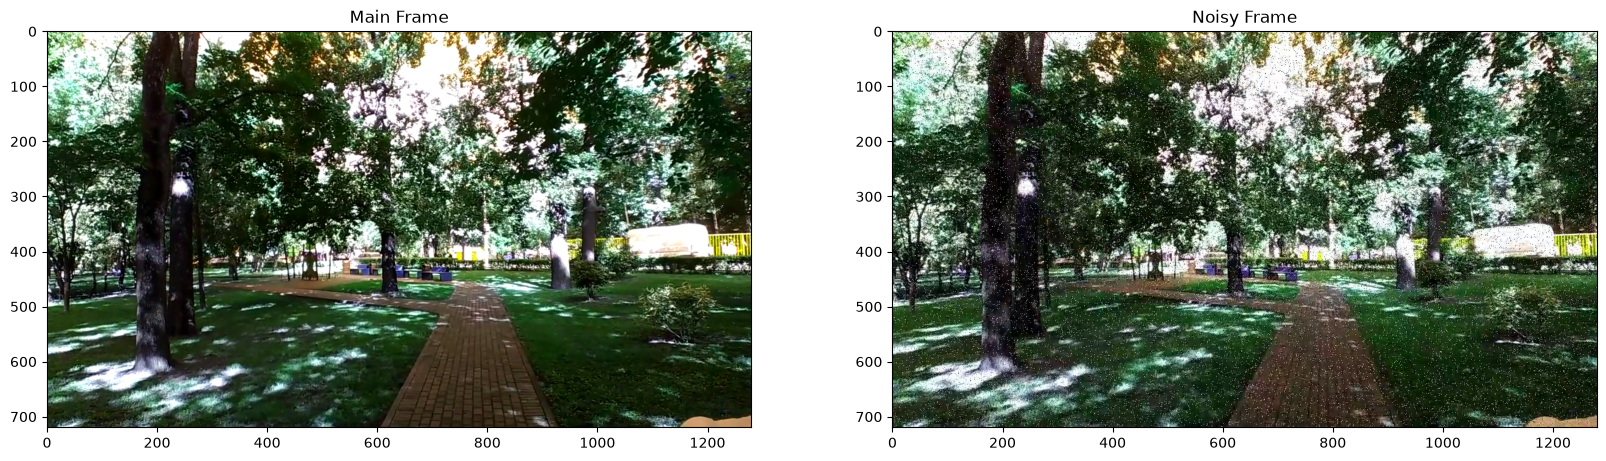

In [43]:
cap = cv2.VideoCapture("park_video.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, 200)
ret, main_frame = cap.read()

cap2 = cv2.VideoCapture("noisy_video.mp4")
cap2.set(cv2.CAP_PROP_POS_FRAMES, 200)
ret, noisy_frame = cap2.read()

plt.figure(figsize=[20,10])
plt.subplot(121); plt.imshow(main_frame); plt.title('Main Frame');
plt.subplot(122); plt.imshow(noisy_frame); plt.title('Noisy Frame');

cap.release()
cap2.release()

#### <div style="direction:rtl;text-align:right"> سوال سوم؛ حذف نویز از ویدیو </div>

<div style="direction:rtl;text-align:right">
با توجه به نتایج بدست آمده در بخش دوم، بهترین عملکرد در حذف نویز فلفل نمکی مربوط به فیلتر Median است. این فیلتر با انتخاب میانه‌ی پیکسل‌های همسایه بعنوان پیکسل خروجی می‌تواند اثر پیکسل‌های نویزدار را کاهش دهد.
    <br/>
از طرفی اندازه‌ی کرنل تعیین می‌کند چه تعداد از پیکسل‌های همسایه برای محاسبه‌ی یک پیکسل در نظر گرفته شود. هر چه این مقدار بیشتر باشد طبیعتا تصویر خروجی یکدست تر و بدون نویز خواهد بود.
    <br/>
اما زیاد شدن بیش از حد ابعاد کرنل جزئیات تصویر را از بین می‌برد چراکه مقدار پیکسل‌های مجاور به یکدیگر نزدیک شده‌اند. بنابراین و با چند آزمون و خطا، به نظر می‌رسد که کرنل 5*5 برای ویدیوی ما خروجی قابل قبولی را تولید کند.
    <br/>
<a href="https://drive.google.com/file/d/1uvd0szjLcVRHVfzGEsbfEMyFd8noA0vI/view?usp=drive_link">ویدیوی فیلترشده از اینجا قابل مشاهده است.</a>
</div>

In [44]:
cap = cv2.VideoCapture("noisy_video.mp4")
out = cv2.VideoWriter('filtered_video_1.MP4', fourcc, fps, frame_size)

res = applyFilter(
    lambda frame: cv2.medianBlur(frame, 5), 
    cap, out
)
print(f'Filtered {res}')

Filtered video successfully created!


#### <div style="direction:rtl;text-align:right"> سوال چهارم؛ مقایسه روش‌های حذف نویز </div>

<div style="direction:rtl;text-align:right">
این بار از فیلتر Gaussian برای رفع نویز استفاده کردیم.
    <br/>
<a href="https://drive.google.com/file/d/1MWjszBCTdYXrUpWr7ZWcoVqmLoXWIi11/view?usp=drive_link">ویدیوی فیلترشده از اینجا قابل مشاهده است.</a>
</div>

In [45]:
cap = cv2.VideoCapture("noisy_video.mp4")
out = cv2.VideoWriter('filtered_video_2.MP4', fourcc, fps, frame_size)

res = applyFilter(
    lambda frame: cv2.GaussianBlur(frame, (5, 5), 0), 
    cap, out
)
print(f'Filtered {res}')

Filtered video successfully created!


##### <div style="direction:rtl;text-align:right"> کدام فیلتر در حذف نویز عملکرد بهتری داشته است؟ </div>

<div style="direction:rtl;text-align:right">
همانطور که از ویدیوهای خروجی پیداست، فیلتر Median عملکرد بهتری در حذف نویز فلفل نمکی داشت.
    <br/>
نویز فلفل نمکی پیکسل‌هایی با مقادیر بسیار زیاد یا بسیار کم هستند. فیلتر Median مقدار میانه‌ی پیکسل‌های اطراف را انتخاب می‌کند و جای پیکسل‌ قبلی قرار می‌دهد. بنابراین پیکسل‌های دارای نویز که با اطرافشان معمولا تفاوت زیادی دارند، کمرنگ تر می‌شوند.
    <br/>
در مقابل، فیلتر Gaussian میانگین وزنی پیکسل‌های اطراف را محاسبه و جایگزین پیکسل قبلی می‌کند. در واقع این فیلتر به نوعی اثر پیکسل‌های نویزدار را روی پیکسل‌های همسایه پخش می‌کند.
    <br/>
</div>

##### <div style="direction:rtl;text-align:right"> کدام فیلتر در حفظ جزئیات و لبه‌ها عملکرد بهتری داشته است؟ </div>

<div style="direction:rtl;text-align:right">
فیلتر Median جزئیات خروجی را نیز بهتر حفظ کرده است.
    <br/>
فیلتر Gaussian با میانگین گیری از پیکسل‌های همسایه، تضاد بین پیکسل‌های مجاور را کم می‌کند و باعث محو شدن لبه‌ها و جزئیات می‌شود.
    <br/>
در مقابل اگرچه Median نیز ممکن است جزئیات تصویر را تحت تاثیر قرار دهد، اما چون مقدار میانه را انتخاب می‌کند، نسبت به پیکسل‌های پرت حساسیت کمتری دارد.
    <br/>
</div>

##### <div style="direction:rtl;text-align:right"> چرا اعمال فیلترها باعث تار شدن تصویر شده است؟ </div>

<div style="direction:rtl;text-align:right">
فیلترهای استفاده شده، تغییرات شدت روشنایی بین پیکسل‌های مجاور را کاهش می‌دهند.
    <br/>
بنابراین با اعمال فیلتر روی تصویر، پیکسل‌های مجاور به یکدیگر نزدیک‌تر شده و در نتیجه تصویر تار تر می‌شود. این اتفاق می‌تواند اطلاعاتی از تصویر را نیز حذف کند.
</div>

#### <div style="direction:rtl;text-align:right"> سوال پنجم؛ بررسی و تحلیل نتایج </div>

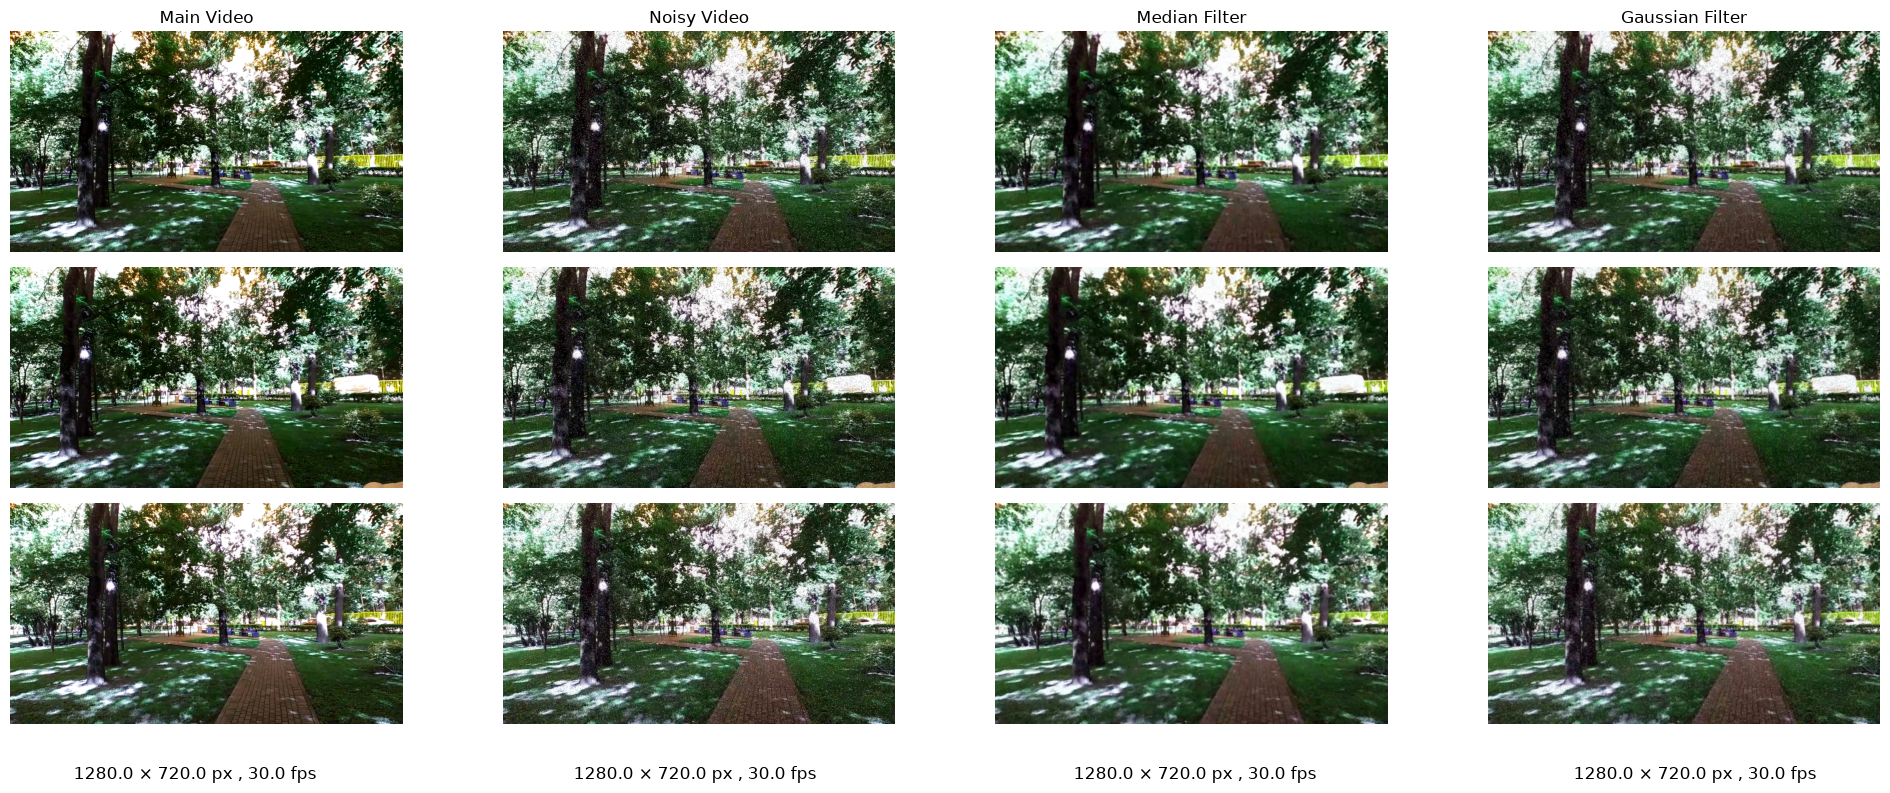

In [51]:
captions = []
videos = [
    ("park_video.mp4", "Main Video"),
    ("noisy_video.mp4", "Noisy Video"),
    ("filtered_video_1.MP4", "Median Filter"),
    ("filtered_video_2.MP4", "Gaussian Filter"),
]
frame_no = [20, 200, 420]

fig, axes = plt.subplots(3, 4, figsize=(20, 8))

for i in range(3):
    for j, (video, title) in enumerate(videos):

        cap = cv2.VideoCapture(video)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no[i])
        ret, frame = cap.read()
    
        axes[i, j].imshow(frame, vmin=0, vmax=255)
        if i == 0:
            axes[i, j].set_title(title)
            captions.append((f'{cap.get(cv2.CAP_PROP_FRAME_WIDTH)} × {cap.get(cv2.CAP_PROP_FRAME_HEIGHT)} px , {cap.get(cv2.CAP_PROP_FPS)} fps'))
        axes[i, j].axis("off")
        
        cap.release()

for j, caption in enumerate(captions):
    fig.text((j + 0.5) / 4, 0.02, caption,
             ha="center", fontsize=12)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

<div style="direction:rtl;text-align:right">
در تصاویر بالا به دلیل اندازه‌ی کوچک تصاویر تفاوت‌ها محسوس نیست. 
    <br/>
اما با مشاهده‌ی ویدیوهای اصلی مشخص است که فیلتر Median نسبت به Gaussian جزئیات و مرز اجسام را بهتر حفظ می‌کند. 
    <br/>
فیلتر Gaussian به دلیل استفاده از میانگین وزنی پیکسل‌های مجاور، باعث هموار شدن تغییرات شدت روشنایی شده و در نتیجه جزئیات ظریف محیط، بافت سطوح و لبه اشیا تا حدی محو می‌شوند. 
    <br/>
در مقابل، فیلتر Median با جایگزین کردن هر پیکسل با مقدار میانه همسایگی آن، ضمن حذف مؤثر نویز فلفل نمکی، تغییرات لبه‌ها را بهتر حفظ می‌کند؛ هرچند این فیلتر نیز ممکن است جزئیات بسیار کوچک را از بین ببرد.
</div>

<div style="direction:rtl;text-align:right">
در مورد اجسام متحرک نیز هر دو فیلتر می‌توانند باعث کاهش وضوح جزئیات، به‌خصوص در بخش‌هایی از اجسام که حرکت سریع‌تری دارند، شوند.
    <br/>
فیلتر Gaussian معمولاً ظاهر نرم‌تر و محوتری در اطراف اجسام ایجاد می‌کند، درحالی‌که Median شکل و مرز اجسام متحرک را بهتر حفظ می‌کند.
    <br/>
البته باید توجه داشت که این فیلترها به‌صورت مستقل روی هر فریم اعمال می‌شوند و اطلاعات زمانی بین فریم‌ها را در نظر نمی‌گیرند؛
بنابراین مستقیماً موجب حذف تاری ناشی از حرکت یا بهبود پیوستگی حرکت نمی‌شوند. در مجموع، برای ویدیوی دارای نویز Salt & Pepper، فیلتر Median انتخاب مناسب‌تری است، زیرا تعادل بهتری میان حذف نویز و حفظ جزئیات تصویر برقرار می‌کند.
</div>

<div style="direction:rtl;text-align:right">
همچنین همانطور که در خروجی زیر تصاویر مشخص است، نرخ فریم و ابعاد ویدیوهای خروجی تغییری نسبت به ویدیوی اصلی نداشته است چراکه برای تولید این ویدیوها، از فریم‌ها و نرخ فریم همان ویدیوی اولیه استفاده شده است.
</div>